In [169]:
#pandas to read the csv
import pandas as pd

#import pathlib to manage file paths
import pathlib

#for plotting
import matplotlib.pyplot as plt

#for model fit and statistics
import statsmodels.formula.api as smf

#geopandas to read the YKR grid shapefile
import geopandas as gpd

#import regex
import re


In [41]:
#set notebook path
NOTEBOOK_PATH = pathlib.Path().resolve()

#set the input data directory
Data_Directory = NOTEBOOK_PATH / "data"

#set the output data directory
Output_Directory = NOTEBOOK_PATH / "outputs"


#get a list of filepaths from the input directory
filepaths = list( Data_Directory.rglob("*.csv"))

#get a list of filenames from the filepaths using pathlib
filenames = [x.name for x in filepaths]


print(filenames)

['indicators-GPs.data (1).csv', 'indicators-GPs.data (2).csv', 'indicators-GPs.data (3).csv', 'indicators-GPs.data (4).csv', 'indicators-GPs.data (5).csv', 'indicators-GPs.data (6).csv', 'indicators-GPs.data (7).csv', 'indicators-GPs.data (8).csv', 'indicators-GPs.data (9).csv', 'indicators-GPs.data.csv']


In [42]:
#empty list to store the files
files = []

for filepath in filepaths:
    files.append(pd.read_csv(filepath, sep = ",", low_memory=False))

rows = []
total_rows = 0
for file in files:
    rows.append(len(file))
    total_rows = total_rows + len(file)



data = pd.concat(files, ignore_index=True, axis=0)

print(len(data))
print(total_rows)



216414
216414


In [43]:
data[["Indicator ID", "Indicator Name"]].drop_duplicates()

,Indicator ID,Indicator Name
0,91337,New cancer cases (Crude incidence rate)
401,92600,Bowel cancer screening coverage: aged 60 to 74...
725,92605,Urgent suspected cancer referrals (Indirectly ...
1043,92608,Urgent suspected cancer referrals resulting in...
1361,92609,New cancer cases treated resulting from an urg...
1679,93468,Proportion of GP registered populations by age...
4267,93725,Cervical screening coverage: aged 25 to 49 yea...
4672,93726,Cervical screening coverage: aged 50 to 64 yea...
5077,94063,Breast screening coverage: aged 53 to 70 years...
5158,94240,Deprivation score (IMD 2025)


In [91]:
breast_cancer_data = data.loc[(data["Area Type"] == "GPs") & (data["Indicator ID"].isin([94063, 94240, 91340]))]

In [92]:
breast_cancer_data.to_csv(Output_Directory/"gm_practice_screening.csv", index = False)

In [93]:
breast_cancer_data["Time period"].drop_duplicates()

5079    2022/23
5106    2023/24
5133    2024/25
5159       2025
5876    2009/10
5903    2010/11
5930    2011/12
5957    2012/13
5984    2013/14
6011    2014/15
6038    2015/16
6065    2016/17
6092    2017/18
6119    2018/19
6146    2019/20
6173    2020/21
6200    2021/22
Name: Time period, dtype: str

In [94]:
breast_cancer_data_2425 = breast_cancer_data.loc[breast_cancer_data["Time period"].isin(["2024/25", "2025"])]

In [95]:
breast_cancer_data_2425.to_csv(Output_Directory/"gm_practice_screening_2425.csv", index = False)
len(breast_cancer_data_2425 )

1202

In [96]:
breast_cancer_data_2425["Indicator ID"].value_counts()

Indicator ID
94063    406
94240    405
91340    391
Name: count, dtype: int64

In [97]:
gp_wise_data = breast_cancer_data_2425.pivot(index=["Area Code", "Area Name", "Parent Name"], columns= "Indicator ID", values=["Value", "Count", "Denominator"])

In [98]:
gp_wise_data.head()

Value  \
Indicator ID                                                          91340   
Area Code Area Name                Parent Name                                
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   59.090909   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   60.000000   
P82003    Kildonan House           Greater Manchester ICB - 00T   68.888889   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   53.571429   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   66.666667   

                                                                             \
Indicator ID                                                          94063   
Area Code Area Name                Parent Name                                
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   74.449339   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   64.084507   
P82003    Kildonan House           Greater Manchester ICB - 00T   76.271186   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   66.666667   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   76.795580   

                                                                          \
Indicator ID                                                       94240   
Area Code Area Name                Parent Name                             
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   37.805   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   40.686   
P82003    Kildonan House           Greater Manchester ICB - 00T   19.422   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   41.867   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   18.978   

                                                                  Count  \
Indicator ID                                                      91340   
Area Code Area Name                Parent Name                            
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    65.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    60.0   
P82003    Kildonan House           Greater Manchester ICB - 00T   155.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    75.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    80.0   

                                                                          \
Indicator ID                                                       94063   
Area Code Area Name                Parent Name                             
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    845.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    455.0   
P82003    Kildonan House           Greater Manchester ICB - 00T   1350.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    540.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    695.0   

                                                                        \
Indicator ID                                                     94240   
Area Code Area Name                Parent Name                           
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    NaN   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    NaN   
P82003    Kildonan House           Greater Manchester ICB - 00T    NaN   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    NaN   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    NaN   

                                                                 Denominator  \
Indicator ID                                                           91340   
Area Code Area Name                Parent Name                                 
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T        110.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T        1

In [99]:
gp_wise_data = gp_wise_data.drop(columns =[("Count",94240), ("Denominator", 94240)])

In [100]:
gp_wise_data.head()

Value  \
Indicator ID                                                          91340   
Area Code Area Name                Parent Name                                
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   59.090909   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   60.000000   
P82003    Kildonan House           Greater Manchester ICB - 00T   68.888889   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   53.571429   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   66.666667   

                                                                             \
Indicator ID                                                          94063   
Area Code Area Name                Parent Name                                
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   74.449339   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   64.084507   
P82003    Kildonan House           Greater Manchester ICB - 00T   76.271186   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   66.666667   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   76.795580   

                                                                          \
Indicator ID                                                       94240   
Area Code Area Name                Parent Name                             
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   37.805   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   40.686   
P82003    Kildonan House           Greater Manchester ICB - 00T   19.422   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   41.867   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   18.978   

                                                                  Count  \
Indicator ID                                                      91340   
Area Code Area Name                Parent Name                            
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    65.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    60.0   
P82003    Kildonan House           Greater Manchester ICB - 00T   155.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    75.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    80.0   

                                                                          \
Indicator ID                                                       94063   
Area Code Area Name                Parent Name                             
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    845.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    455.0   
P82003    Kildonan House           Greater Manchester ICB - 00T   1350.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    540.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    695.0   

                                                                 Denominator  \
Indicator ID                                                           91340   
Area Code Area Name                Parent Name                                 
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T        110.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T        100.0   
P82003    Kildonan House           Greater Manchester ICB - 00T        225.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T        140.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T        120.0   

                                                                          
Indicator ID                                                       94063  
Area Code Area Name                Parent Name                            
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   1135.0  
P82002    Pikes Lane 1             Greater M

In [101]:
gp_wise_data.columns

MultiIndex([(      'Value', 91340),
            (      'Value', 94063),
            (      'Value', 94240),
            (      'Count', 91340),
            (      'Count', 94063),
            ('Denominator', 91340),
            ('Denominator', 94063)],
           names=[None, 'Indicator ID'])

In [102]:
gp_wise_data.columns = ["uptake_pct", "coverage_pct", "depr_score", "uptake_count", "coverage_count", "uptake_denominator", "coverage_denominator"]

In [103]:
gp_wise_data = gp_wise_data.reset_index()
gp_wise_data.head()

,Area Code,Area Name,Parent Name,uptake_pct,coverage_pct,depr_score,uptake_count,coverage_count,uptake_denominator,coverage_denominator
0,P82001,The Dunstan Partnership,Greater Manchester ICB - 00T,59.090909,74.449339,37.805,65.0,845.0,110.0,1135.0
1,P82002,Pikes Lane 1,Greater Manchester ICB - 00T,60.000000,64.084507,40.686,60.0,455.0,100.0,710.0
2,P82003,Kildonan House,Greater Manchester ICB - 00T,68.888889,76.271186,19.422,155.0,1350.0,225.0,1770.0
3,P82004,Swan Lane Medical Centre,Greater Manchester ICB - 00T,53.571429,66.666667,41.867,75.0,540.0,140.0,810.0
4,P82005,Stable Fold Surgery,Greater Manchester ICB - 00T,66.666667,76.795580,18.978,80.0,695.0,120.0,905.0


In [104]:
gp_wise_data.to_csv(Output_Directory/"gm_practice_wise_breast_cancer_data_2425.csv", index = False)

In [105]:
gp_wise_data.isna().sum()

Area Code                0
Area Name                0
Parent Name              0
uptake_pct              15
coverage_pct             0
depr_score               1
uptake_count            15
coverage_count           0
uptake_denominator      15
coverage_denominator     0
dtype: int64

In [106]:
gp_wise_uptake = gp_wise_data.dropna()

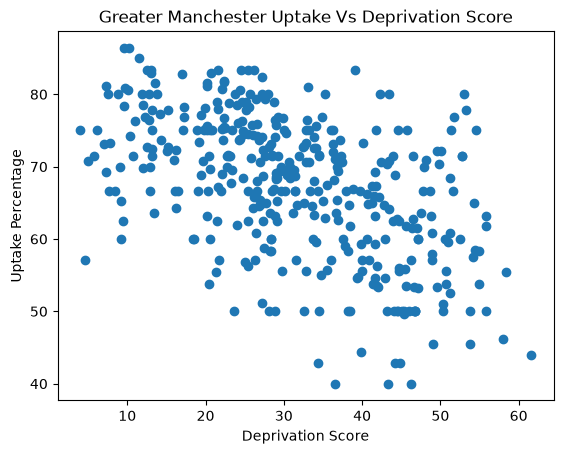

In [132]:
plt.scatter(gp_wise_uptake["depr_score"], gp_wise_uptake["uptake_pct"])
plt.xlabel("Deprivation Score"); plt.ylabel("Uptake Percentage"); plt.title("Greater Manchester Uptake Vs Deprivation Score")
plt.savefig(Output_Directory/"uptake_vs_depr.png", dpi=300, bbox_inches="tight")
plt.show()

In [112]:
model = smf.ols("uptake_pct ~ depr_score", data=gp_wise_uptake).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.271
Model:                            OLS   Adj. R-squared:                  0.269
Method:                 Least Squares   F-statistic:                     144.7
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.50e-28
Time:                        15:33:19   Log-Likelihood:                -1383.4
No. Observations:                 391   AIC:                             2771.
Df Residuals:                     389   BIC:                             2779.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     79.7819      1.125     70.904      0.0

In [116]:
gp_wise_coverage = gp_wise_data.dropna(subset=["depr_score"])

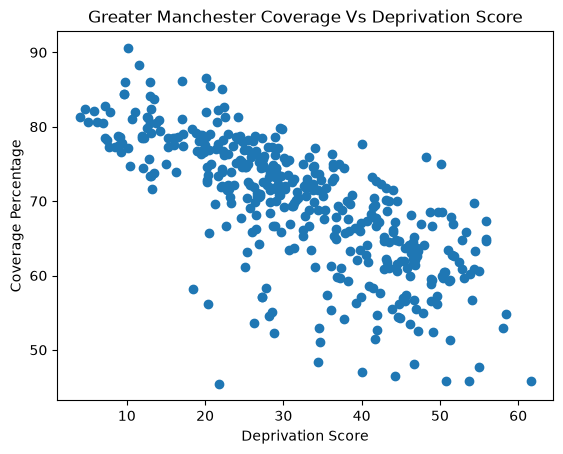

In [133]:
plt.scatter(gp_wise_coverage["depr_score"], gp_wise_coverage["coverage_pct"])
plt.xlabel("Deprivation Score"); plt.ylabel("Coverage Percentage"); plt.title("Greater Manchester Coverage Vs Deprivation Score")
plt.savefig(Output_Directory/"coverge_vs_depr.png", dpi=300, bbox_inches="tight")
plt.show()

In [118]:
model = smf.ols("coverage_pct ~ depr_score", data=gp_wise_coverage).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           coverage_pct   R-squared:                       0.499
Model:                            OLS   Adj. R-squared:                  0.498
Method:                 Least Squares   F-statistic:                     401.6
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.77e-62
Time:                        15:49:14   Log-Likelihood:                -1324.4
No. Observations:                 405   AIC:                             2653.
Df Residuals:                     403   BIC:                             2661.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     85.3738      0.855     99.903      0.0

In [121]:
gp_wise_coverage = gp_wise_coverage.loc[gp_wise_coverage["coverage_pct"] != 25]

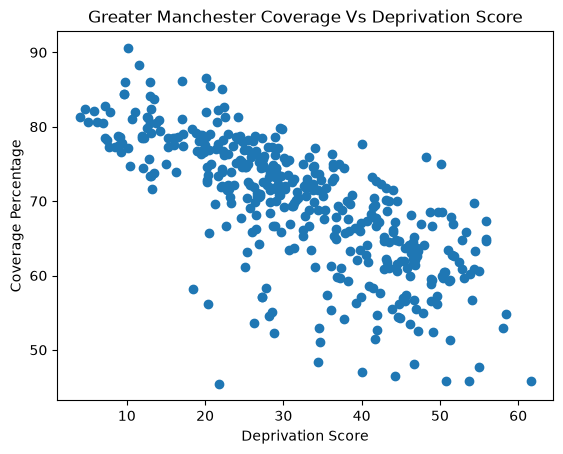

In [134]:
plt.scatter(gp_wise_coverage["depr_score"], gp_wise_coverage["coverage_pct"])
plt.xlabel("Deprivation Score"); plt.ylabel("Coverage Percentage"); plt.title("Greater Manchester Coverage Vs Deprivation Score")
plt.savefig(Output_Directory/"coverage_vs_depr_adjusted.png", dpi=300, bbox_inches="tight")
plt.show()

In [130]:
model = smf.ols("coverage_pct ~ depr_score", data=gp_wise_coverage).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           coverage_pct   R-squared:                       0.523
Model:                            OLS   Adj. R-squared:                  0.522
Method:                 Least Squares   F-statistic:                     441.6
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.09e-66
Time:                        16:44:06   Log-Likelihood:                -1299.0
No. Observations:                 404   AIC:                             2602.
Df Residuals:                     402   BIC:                             2610.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     85.3640      0.809    105.525      0.0

In [136]:
lsoas = gpd.read_file(Data_Directory/"aac0602f-d4b1-40b2-b82f-fce8b447ba0c.gdb")

C:\Users\Public\anaconda3\envs\autogis\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts.  The processing may be really slow.  You can skip the processing by setting METHOD=SKIP.
  return ogr_read(


In [141]:
imd_scores = pd.read_excel(Data_Directory/"File_5_IoD2025_Scores_for_the_Indices_of_Deprivation.xlsx", sheet_name="IoD2025 Scores")

In [142]:
lsoas.head()

,LSOA21CD,LSOA21NM,LSOA21NMW,BNG_E,BNG_N,LAT,LONG,GlobalID,SHAPE_Length,SHAPE_Area,geometry
0,E01000001,City of London 001A,,532123,181632,51.518169,-0.097150,{86214465-5CF4-4E8F-9492-3667471C42D6},2289.743177,133759.153546,"MULTIPOLYGON (((532105.312 182010.574, 532162...."
1,E01000002,City of London 001B,,532480,181715,51.518829,-0.091970,{CD40C491-6567-405F-8C18-426E17B356CE},2486.578125,225673.949016,"MULTIPOLYGON (((532634.497 181926.016, 532619...."
2,E01000003,City of London 001C,,532239,182033,51.521740,-0.095330,{7FD27AAF-D858-4E46-9099-92B43F66B948},1142.183482,57288.376414,"MULTIPOLYGON (((532135.138 182198.131, 532158...."
3,E01000005,City of London 001E,,533581,181283,51.514690,-0.076280,{7E76A16A-028F-4F49-84B5-6E5A67322F3C},2167.942170,190508.858519,"MULTIPOLYGON (((533808.018 180767.774, 533649...."
4,E01000006,Barking and Dagenham 016A,,544994,184274,51.538750,0.089317,{25AB047E-6FCF-4F76-9176-E92E44C0E097},1935.412725,144195.364528,"MULTIPOLYGON (((545122.049 184314.931, 545271...."


In [143]:
imd_scores.head()

,LSOA code (2021),LSOA name (2021),Local Authority District code (2024),Local Authority District name (2024),Index of Multiple Deprivation (IMD) Score,Income Score (rate),Employment Score (rate),"Education, Skills and Training Score",Health Deprivation and Disability Score,Crime Score,Barriers to Housing and Services Score,Living Environment Score,Income Deprivation Affecting Children Index (IDACI) Score (rate),Income Deprivation Affecting Older People (IDAOPI) Score (rate),Children and Young People Sub-domain Score,Adult Skills Sub-domain Score,Geographical Barriers Sub-domain Score,Wider Barriers Sub-domain Score,Indoors Sub-domain Score,Outdoors Sub-domain Score
0,E01000001,City of London 001A,E09000001,City of London,8.742,0.013,0.014,0.004,-1.771,-2.220,10.950,69.345,0.039,0.012,-2.902,0.030,4.437,0.688,1.207,1.414
1,E01000002,City of London 001B,E09000001,City of London,4.722,0.018,0.010,0.169,-1.549,-2.277,6.703,43.890,0.076,0.026,-1.830,0.032,3.589,-0.628,0.355,1.839
2,E01000003,City of London 001C,E09000001,City of London,9.250,0.107,0.064,3.269,-0.292,-0.765,9.735,41.163,0.250,0.153,-0.756,0.113,2.509,0.358,0.318,1.679
3,E01000005,City of London 001E,E09000001,City of London,19.884,0.211,0.104,17.852,0.436,-0.626,24.623,38.695,0.459,0.625,-0.814,0.305,2.914,4.091,0.012,2.065
4,E01000006,Barking and Dagenham 016A,E09000002,Barking and Dagenham,25.307,0.343,0.120,25.442,-0.372,-0.072,38.025,29.616,0.640,0.156,-0.199,0.336,13.049,6.204,0.399,0.400


In [148]:
lsoas_imd = lsoas.merge(imd_scores, left_on="LSOA21CD", right_on="LSOA code (2021)", how="inner")

In [155]:
mcr_lsoas = lsoas_imd.loc[lsoas_imd["Local Authority District name (2024)"].isin(["Bolton", "Bury", "Manchester", "Oldham", "Rochdale", "Salford", "Stockport", "Tameside", "Trafford", "Wigan"])]

districts = mcr_lsoas.dissolve(by="Local Authority District name (2024)")

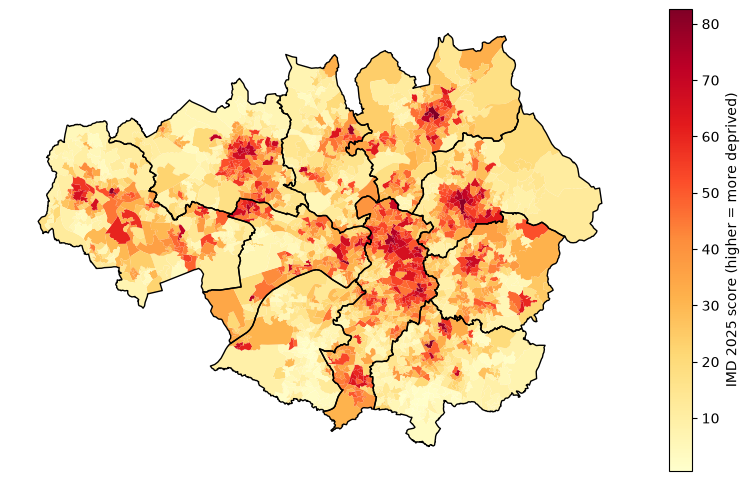

In [159]:
fig, ax = plt.subplots(figsize=(10, 10))

mcr_lsoas.plot(column="Index of Multiple Deprivation (IMD) Score", cmap="YlOrRd", legend=True, legend_kwds={"shrink": 0.6, "label": "IMD 2025 score (higher = more deprived)"}, ax=ax)
districts.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1)

ax.set_axis_off()
plt.savefig(Output_Directory/"gm_lsoas_with_imd.png")
plt.show()

In [163]:
gp_postcodes=pd.read_csv(Data_Directory/"E92000001.addresses.csv", sep = ",")

In [164]:
gp_postcodes.head()

,Code,Name,Address,Postcode
0,A81001,The Densham Surgery,"The Health Centre, Lawson Street, Stockton-On-...",TS18 1HU
1,A81002,Queens Park Medical Centre,"Queens Park Medical Ctr, Farrer Street, Stockt...",TS18 2AW
2,A81004,Acklam Medical Centre,"Trimdon Avenue, Acklam, Middlesbrough, Cleveland",TS5 8SB
3,A81005,Springwood Surgery,"Rectory Lane, Guisborough",TS14 7DJ
4,A81006,Tennant Street Medical Practice,"Tennant St Medical Pract, Farrer Street, Stock...",TS18 2AT


In [166]:
mcr_gp_postcodes= gp_wise_data.merge(gp_postcodes, left_on="Area Code", right_on="Code", how="left")

In [167]:
len(mcr_gp_postcodes)

406

In [168]:
mcr_gp_postcodes.head()

,Area Code,Area Name,Parent Name,uptake_pct,coverage_pct,depr_score,uptake_count,coverage_count,uptake_denominator,coverage_denominator,Code,Name,Address,Postcode
0,P82001,The Dunstan Partnership,Greater Manchester ICB - 00T,59.090909,74.449339,37.805,65.0,845.0,110.0,1135.0,P82001,The Dunstan Partnership,"Breightmet Health Centre, Breightmet Fold Lane...",BL2 6NT
1,P82002,Pikes Lane 1,Greater Manchester ICB - 00T,60.000000,64.084507,40.686,60.0,455.0,100.0,710.0,P82002,Pikes Lane 1,"The Pikes Lane Centre, Deane Road, Bolton, Lan...",BL3 5HP
2,P82003,Kildonan House,Greater Manchester ICB - 00T,68.888889,76.271186,19.422,155.0,1350.0,225.0,1770.0,P82003,Kildonan House,"Ramsbottom Road, Horwich, Bolton",BL6 5NW
3,P82004,Swan Lane Medical Centre,Greater Manchester ICB - 00T,53.571429,66.666667,41.867,75.0,540.0,140.0,810.0,P82004,Swan Lane Medical Centre,"Swan Lane, Bolton, Lancashire",BL3 6TL
4,P82005,Stable Fold Surgery,Greater Manchester ICB - 00T,66.666667,76.795580,18.978,80.0,695.0,120.0,905.0,P82005,Stable Fold Surgery,"119 Church Street, Westhoughton, Bolton",BL5 3SF


In [171]:
mcr_gp_postcodes["Postcode"].nunique()

340

In [179]:
# Extract postcode areas (leading letters) from the practice postcodes
areas = (
    mcr_gp_postcodes["Postcode"]
    .str.upper()
    .str.extract(r"^([A-Z]+)")[0]   # [0] selects the captured column
    .unique()
    .tolist()
)
print(areas)


['BL', 'M', 'OL', 'SK', 'WA', 'WN']


In [173]:
len(postcodes)

340

In [180]:
#get a list of post code filepaths from the input directory
pc_filepaths = list(Data_Directory.rglob("ONSPD_FEB_2026_UK_*.csv"))

# Keep only the ONSPD files whose area code matches exactly
area_files = [p for p in pc_filepaths if p.stem.split("_")[-1] in areas]
print([p.name for p in area_files])

['ONSPD_FEB_2026_UK_BL.csv', 'ONSPD_FEB_2026_UK_M.csv', 'ONSPD_FEB_2026_UK_OL.csv', 'ONSPD_FEB_2026_UK_SK.csv', 'ONSPD_FEB_2026_UK_WA.csv', 'ONSPD_FEB_2026_UK_WN.csv']


In [182]:
#Check the column names in one file
print(pd.read_csv(area_files[0], nrows=5).columns.tolist())

['pcd7', 'pcd8', 'pcds', 'dointr', 'doterm', 'cty25cd', 'ced25cd', 'lad25cd', 'wd25cd', 'parncp25cd', 'usrtypind', 'east1m', 'north1m', 'gridind', 'hlth19cd', 'nhser24cd', 'ctry25cd', 'rgn25cd', 'ssr95cd', 'pcon24cd', 'eer20cd', 'educ23cd', 'ttwa15cd', 'pco19cd', 'itl25cd', 'wdstl05cd', 'oa01cd', 'wdcas03cd', 'npark16cd', 'lsoa01cd', 'msoa01cd', 'ruc01ind', 'oac01ind', 'oa11cd', 'lsoa11cd', 'msoa11cd', 'wz11cd', 'sicbl24cd', 'bua24cd', 'ruc11ind', 'oac11ind', 'lat', 'long', 'lep21cd1', 'lep21cd2', 'pfa23cd', 'imd20ind', 'cal24cd', 'icb23cd', 'oa21cd', 'lsoa21cd', 'msoa21cd', 'ruc21ind']


In [185]:
cols = ["pcds", "east1m", "north1m", "lsoa21cd", "doterm"]
onspd = pd.concat(
    [pd.read_csv(p, usecols=cols, low_memory=False) for p in area_files],
    ignore_index=True,)

In [186]:
mcr_gp_postcodes["pc_key"] = mcr_gp_postcodes["Postcode"].str.upper().str.replace(" ", "", regex=False)
onspd["pc_key"] = onspd["pcds"].str.upper().str.replace(" ", "", regex=False)

In [187]:
# Merge coordinates onto the practices
gp_coords = mcr_gp_postcodes.merge(onspd, on="pc_key", how="left")

In [189]:
print(len(gp_coords))                       
print(gp_coords["east1m"].isna().sum()) 

406
0


In [191]:
gp_points = gpd.GeoDataFrame(
    gp_coords,
    geometry=gpd.points_from_xy(gp_coords["east1m"], gp_coords["north1m"]),
    crs="EPSG:27700",
)

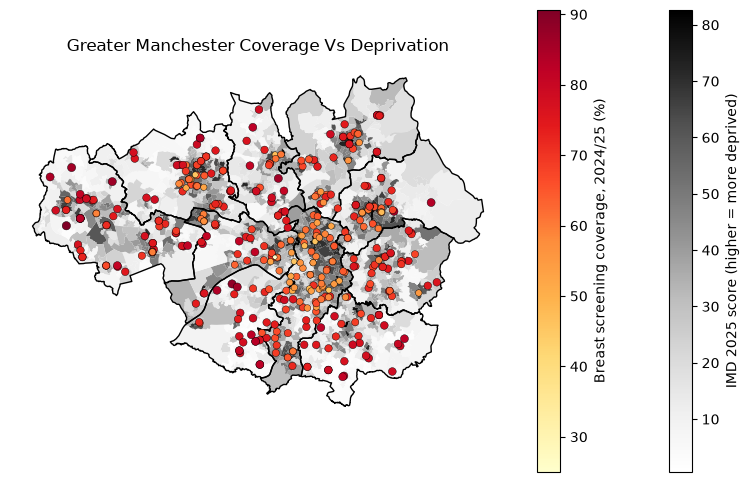

In [207]:
fig, ax = plt.subplots(figsize=(10, 10))

mcr_lsoas.plot(column="Index of Multiple Deprivation (IMD) Score", cmap="Greys", legend=True, legend_kwds={"shrink": 0.6, "label": "IMD 2025 score (higher = more deprived)"}, ax=ax)
districts.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1)
gp_points.plot(ax=ax, column="coverage_pct", cmap ="YlOrRd", markersize = gp_points["coverage_pct"] * 0.4, edgecolor="black", legend=True, legend_kwds={"shrink": 0.6, "label": "Breast screening coverage, 2024/25 (%)"}, linewidth=0.3)

ax.set_axis_off()
ax.set_title("Greater Manchester Coverage Vs Deprivation")
plt.savefig(Output_Directory/"gm_lsoas_with_imd_coverage.png")
plt.show()

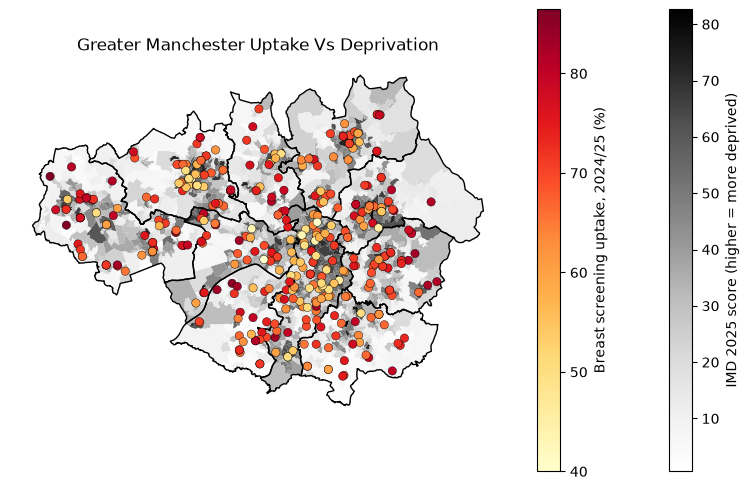

In [208]:
fig1, ax1 = plt.subplots(figsize=(10, 10))

mcr_lsoas.plot(column="Index of Multiple Deprivation (IMD) Score", cmap="Greys", legend=True, legend_kwds={"shrink": 0.6, "label": "IMD 2025 score (higher = more deprived)"}, ax=ax1)
districts.plot(ax=ax1, facecolor="none", edgecolor="black", linewidth=1)
gp_points.plot(ax=ax1, column="uptake_pct", cmap ="YlOrRd", edgecolor="black", legend=True, legend_kwds={"shrink": 0.6, "label": "Breast screening uptake, 2024/25 (%)"}, linewidth=0.3)

ax1.set_axis_off()
ax1.set_title("Greater Manchester Uptake Vs Deprivation")
plt.savefig(Output_Directory/"gm_lsoas_with_imd_uptake.png")
plt.show()